# Auditoria de Calçadas — Treino YOLOv8n
**Checkpoint CPZÃO (CP2 + CP3) — FIAP · Visão Computacional**

Integrante: **Kayky Oliveira Schunck — RM 99756**

Pipeline: imagens do Mapillary (projeto Auditoria Cidadã de Calçadas) → rotulagem no Roboflow → treino YOLOv8n no Colab → métricas → exportação ONNX 320×320 → `yoloinferApp` adaptado (PWA rodando no iPhone).

**Classes:** `buraco`, `calcada_estreita`, `obstaculo`, `rachadura`, `tampa`

> Ambiente: Google Colab com GPU T4 (*Ambiente de execução → Alterar tipo de ambiente → T4 GPU*).

In [1]:
!pip install -q ultralytics roboflow
import torch
print("GPU disponível:", torch.cuda.is_available())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.3 MB/s eta 0:00:00
GPU disponível: True


## 1. Dataset
- **Origem:** fotos do Mapillary publicadas pelo usuário `gabinete_falzoni` (Brás/SP, nov/2025), baixadas com o notebook `01_coleta_mapillary.ipynb`. Das 300 fotos baixadas, **65 foram selecionadas manualmente** por mostrarem defeitos ou obstáculos reais.
- **Rotulagem:** pré-rotulagem com o Auto Label do Roboflow (LLM multimodal) e **revisão manual imagem por imagem** (caixas corrigidas, apagadas ou desenhadas). 63 imagens aprovadas, 2 rejeitadas.
- A API key do Roboflow fica nos *Secrets* do Colab (nome usado: `DATA_API_KEY`).

In [5]:
from google.colab import userdata
from roboflow import Roboflow

# API key guardada nos Secrets do Colab (nome: ROBOFLOW_API_KEY)
rf = Roboflow(api_key=userdata.get('DATA_API_KEY'))
project = rf.workspace("kayky-schunck").project("auditoria-calcadas-9v16a")
version = project.version(1)
dataset = version.download("yolov8")

DATA_YAML = f"{dataset.location}/data.yaml"
print(DATA_YAML)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to auditoria-calcadas-1 in yolov8:: 100%|██████████| 128/128 [00:00<00:00, 2126.09it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
/content/auditoria-calcadas-1/data.yaml


O export do Roboflow veio com todas as imagens em `train`. A célula abaixo refaz a divisão **70/20/10** (semente fixa = 42, reprodutível) e corrige os caminhos do `data.yaml`.

In [9]:
# Garante a divisão 70/20/10 (train/valid/test) e corrige os caminhos do data.yaml
import os, glob, random, shutil, yaml

root = dataset.location
pares = []
for s in ['train', 'valid', 'test']:
    for img in glob.glob(f"{root}/{s}/images/*"):
        base = os.path.splitext(os.path.basename(img))[0]
        lbl = f"{root}/{s}/labels/{base}.txt"
        pares.append((img, lbl if os.path.exists(lbl) else None))

contagem = {s: len(glob.glob(f"{root}/{s}/images/*")) for s in ['train', 'valid', 'test']}
print("Antes:", contagem)

if contagem['valid'] == 0 or contagem['test'] == 0:
    tmp = f"{root}/_todas"
    os.makedirs(f"{tmp}/images", exist_ok=True); os.makedirs(f"{tmp}/labels", exist_ok=True)
    movidos = []
    for img, lbl in pares:
        novo_img = shutil.move(img, f"{tmp}/images/")
        novo_lbl = shutil.move(lbl, f"{tmp}/labels/") if lbl else None
        movidos.append((novo_img, novo_lbl))
    random.seed(42); random.shuffle(movidos)
    n = len(movidos); n_tr = round(n * 0.7); n_va = round(n * 0.2)
    grupos = {'train': movidos[:n_tr], 'valid': movidos[n_tr:n_tr + n_va], 'test': movidos[n_tr + n_va:]}
    for s, itens in grupos.items():
        os.makedirs(f"{root}/{s}/images", exist_ok=True); os.makedirs(f"{root}/{s}/labels", exist_ok=True)
        for img, lbl in itens:
            shutil.move(img, f"{root}/{s}/images/")
            if lbl: shutil.move(lbl, f"{root}/{s}/labels/")
    shutil.rmtree(tmp)

with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)
cfg.update({'path': root, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images'})
with open(DATA_YAML, 'w') as f:
    yaml.safe_dump(cfg, f, allow_unicode=True)

print("Depois:", {s: len(glob.glob(f"{root}/{s}/images/*")) for s in ['train', 'valid', 'test']})

Antes: {'train': 63, 'valid': 0, 'test': 0}
Depois: {'train': 44, 'valid': 13, 'test': 6}


In [ ]:
# Estatísticas do dataset (vão para o README)
import os, glob, yaml
from collections import Counter

with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)
nomes = cfg['names']
print("Classes:", nomes, "\n")

for split in ['train', 'valid', 'test']:
    imgs = glob.glob(f"{dataset.location}/{split}/images/*")
    cont = Counter()
    for lbl in glob.glob(f"{dataset.location}/{split}/labels/*.txt"):
        for linha in open(lbl):
            if linha.strip():
                cont[int(linha.split()[0])] += 1
    print(f"{split:6s} | {len(imgs):3d} imagens | " +
          ", ".join(f"{nomes[i]}: {cont[i]}" for i in range(len(nomes))))

**Estatísticas do dataset (63 imagens, 375 caixas):**

| Classe | Caixas | Descrição usada na rotulagem |
|---|---|---|
| `obstaculo` | 152 | poste, cadeira, caixa, vaso, mercadoria bloqueando a calçada |
| `rachadura` | 94 | fenda/linha de quebra no piso (sem juntas regulares de mosaico) |
| `tampa` | 60 | tampa de concreto/metal, bueiro, boca de lobo |
| `buraco` | 50 | buraco ou pedaço faltando no piso |
| `calcada_estreita` | 19 | trecho de passagem livre estreito demais para cadeira de rodas |

| Split | Imagens | Caixas |
|---|---|---|
| train | 44 | 248 |
| valid | 13 | 85 |
| test | 6 | 42 |

## 2. Treinamento
**YOLOv8n** (CNN de ~3 M de parâmetros, PyTorch/Ultralytics) com *transfer learning* a partir dos pesos do COCO.

O app de referência roda modelos em 192×192. Fizemos dois experimentos para escolher a resolução:

### Experimento 1 — imgsz 192 (padrão do app), early stopping (patience 30)

In [10]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')   # pesos pré-treinados no COCO (transfer learning)
results = model.train(
    data=DATA_YAML,
    epochs=100,
    imgsz=192,
    batch=16,
    patience=30,       # early stopping
    seed=42,
    project='runs',
    name='calcadas',
    exist_ok=True,
)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/auditoria-calcadas-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=192, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=calcadas, nbs=64, nms=None, opset=None, optimize=F

### Experimento 2 — imgsz 320, 150 épocas, sem early stopping

In [11]:
# Experimento: resolução maior e treino mais longo
model = YOLO('yolov8n.pt')
results = model.train(
    data=DATA_YAML,
    epochs=150,
    imgsz=320,
    batch=16,
    patience=0,     # sem early stopping
    seed=42,
    name='calcadas_320',
    exist_ok=True,
)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/auditoria-calcadas-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=calcadas_320, nbs=64, nms=None, opset=None, optimi

### Comparação (conjunto de validação, 13 imagens)

| Experimento | imgsz | épocas | Precision | Recall | mAP@50 | mAP@50-95 |
|---|---|---|---|---|---|---|
| 1 | 192 | 65 (early stop) | 0,907 | 0,044 | 0,062 | 0,040 |
| **2** | **320** | 150 | 0,657 | **0,135** | **0,152** | **0,082** |

Em 192×192 rachaduras e tampas ocupam poucos pixels e o modelo praticamente não as detecta (recall 0). Com 320 o mAP@50 aumentou ~2,5× e o recall ~3×. **Adotamos o modelo de 320** e adaptamos o `yoloinferApp` para entrada 320×320.

## 3. Avaliação no conjunto de teste, curvas e matriz de confusão + exportação ONNX

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2060.6±632.8 MB/s, size: 274.9 KB)
val: Scanning /content/auditoria-calcadas-1/test/labels... 6 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6/6 688.3it/s 0.0s
val: New cache created: /content/auditoria-calcadas-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.2it/s 0.4s
                   all          6         42       0.88      0.108      0.206      0.103
                buraco          4          4      0.731       0.25      0.265       0.13
      calcada_estreita          2          2          1          0      0.019     0.0019
             obstaculo          6         14      0.671      0.292      0.485      0.239
             rachadura          6         17          1          0

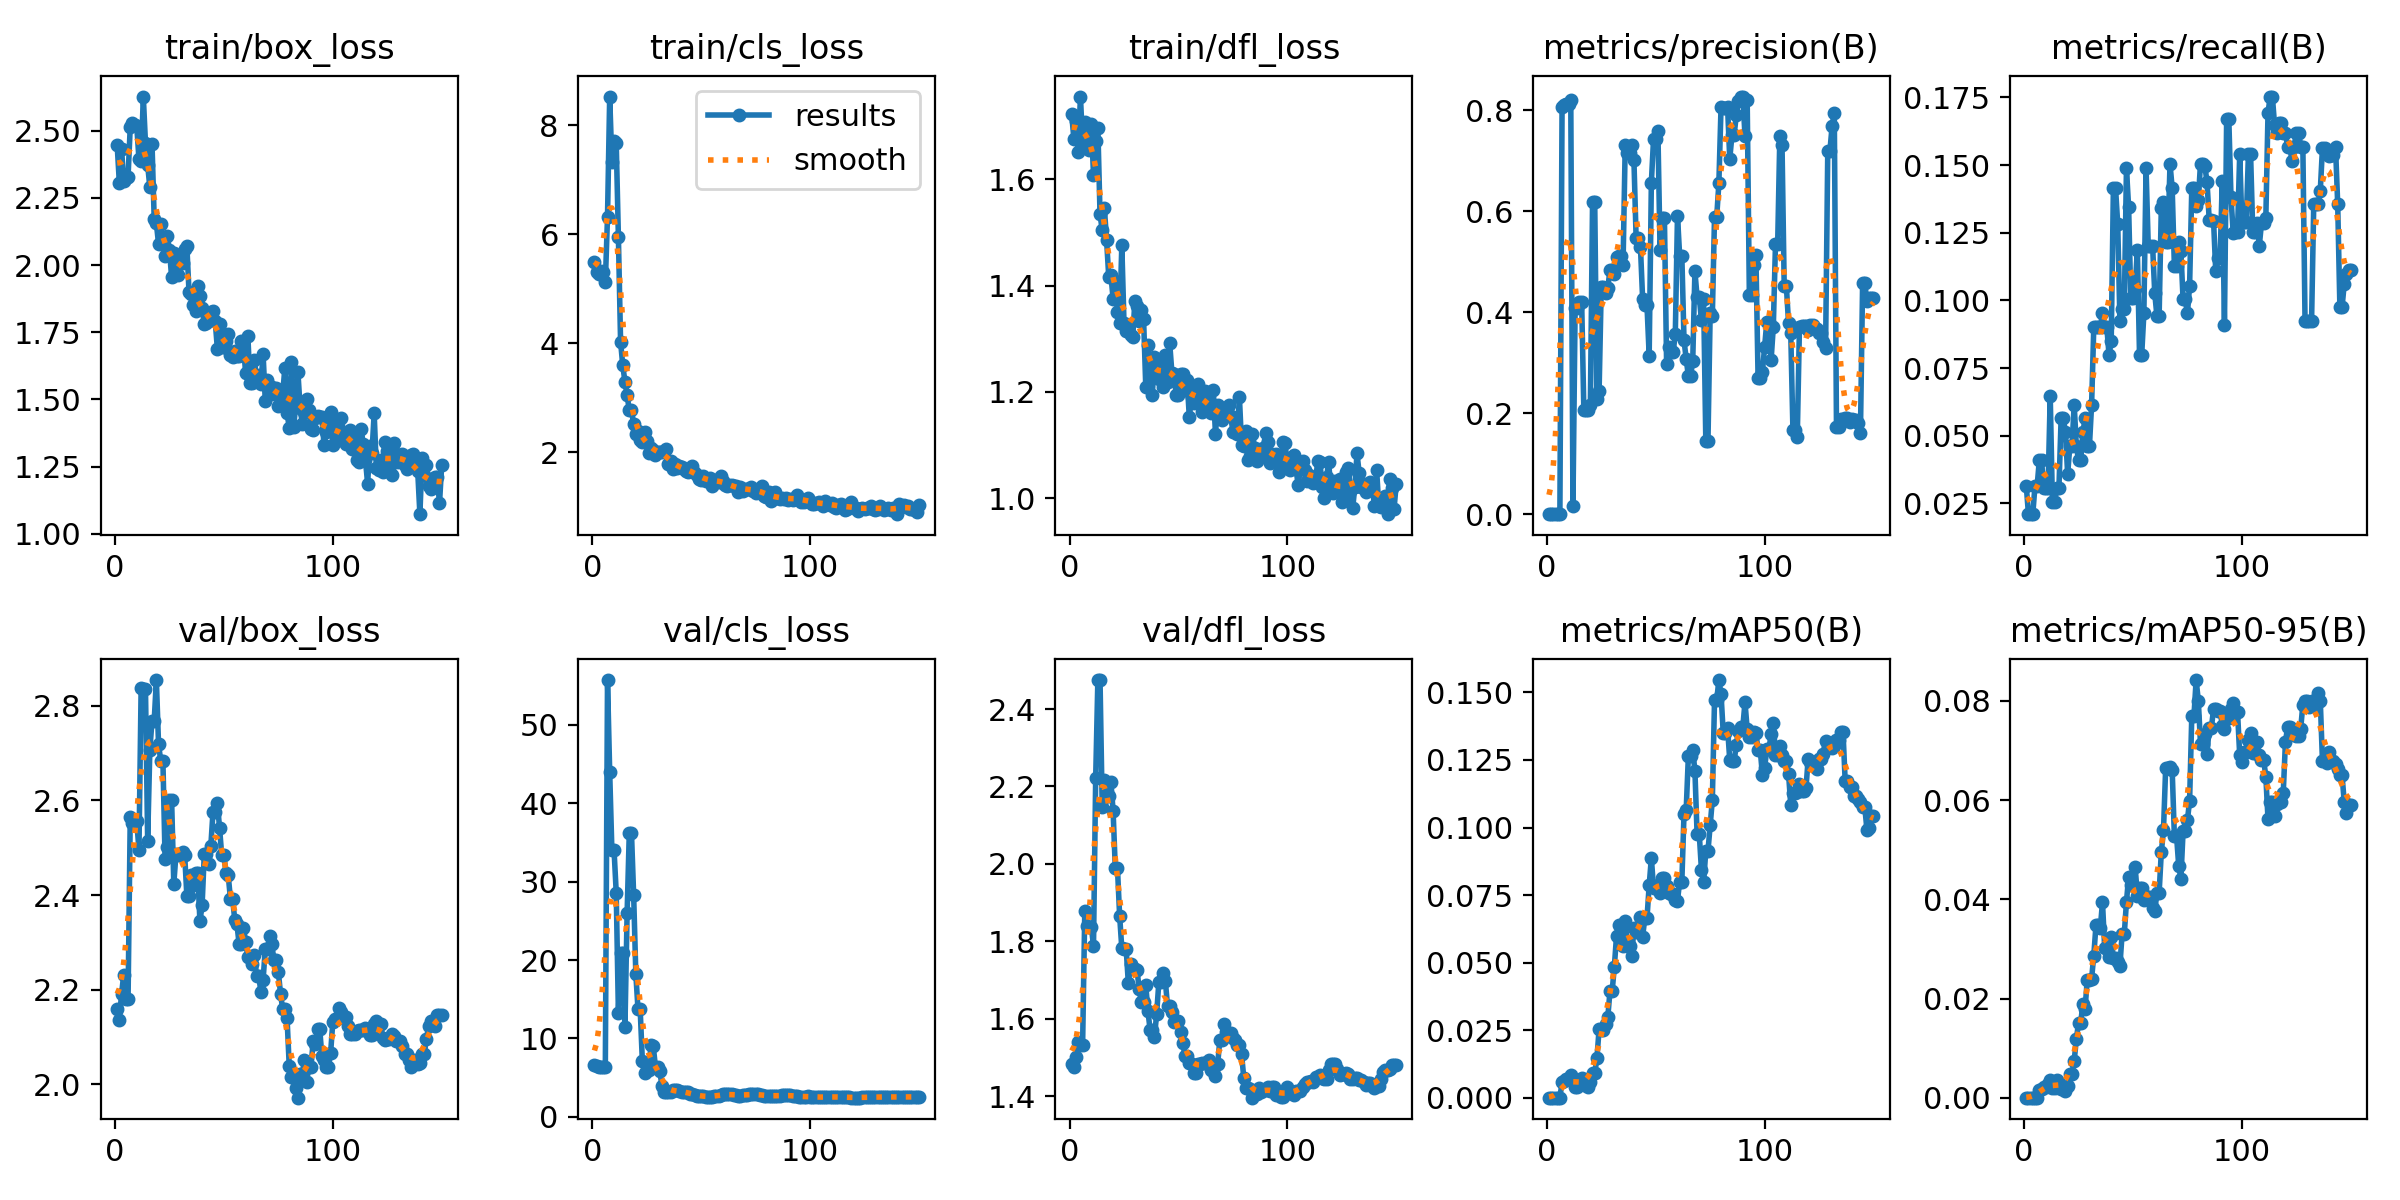

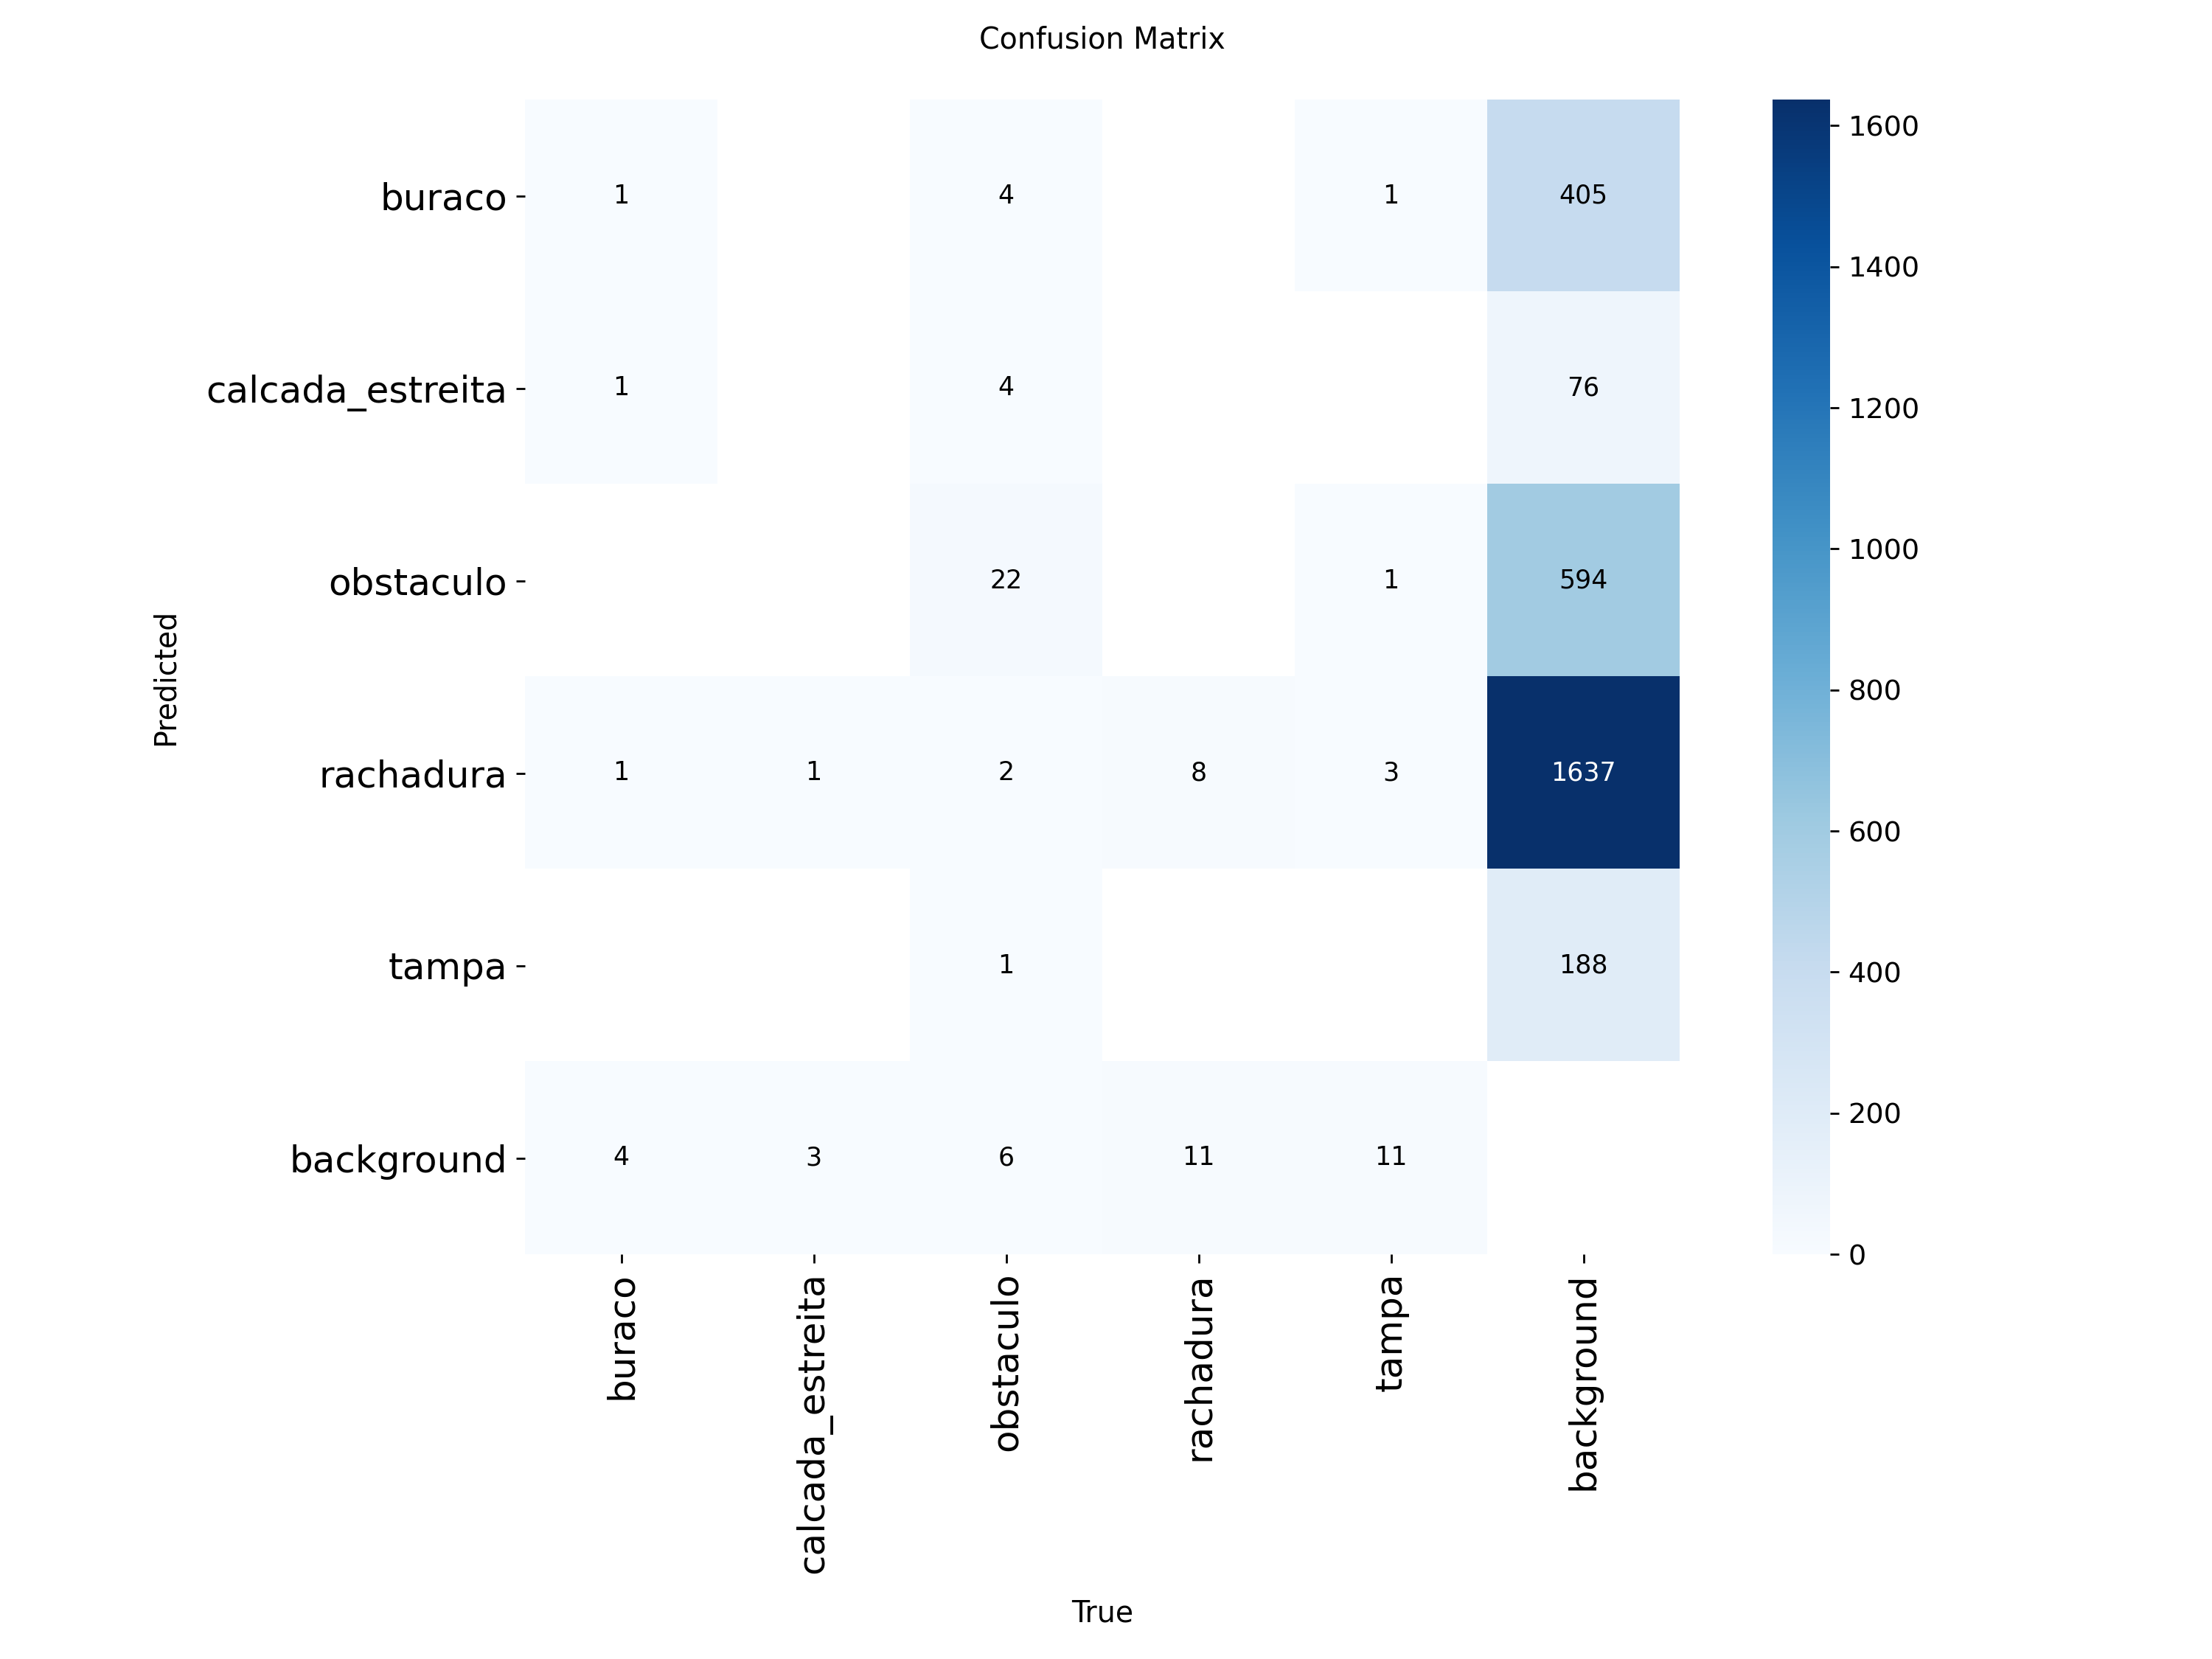

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 2.2 GFLOPs

PyTorch: starting from '/content/runs/detect/calcadas_320/weights/best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 9, 2100) (6.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 237ms
Prepared 4 packages in 561ms
Installed 4 packages in 54ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
from ultralytics import YOLO
from IPython.display import Image, display
import shutil
from google.colab import files

RUN = '/content/runs/detect/calcadas_320'
best = YOLO(f'{RUN}/weights/best.pt')

# Métricas no conjunto de TESTE
m = best.val(data=DATA_YAML, split='test', imgsz=320)
print(f"mAP@50: {m.box.map50:.3f} | Precision: {m.box.mp:.3f} | Recall: {m.box.mr:.3f}")

# Gráficos para o README
for arq in ['results.png', 'confusion_matrix.png']:
    display(Image(filename=f'{RUN}/{arq}', width=800))

# Exporta para o app
onnx = best.export(format='onnx', imgsz=320, simplify=True)
shutil.copy(onnx, 'calcadas_320.onnx')
files.download('calcadas_320.onnx')

### Resultados no conjunto de TESTE (6 imagens, 42 caixas) — modelo 320

| Classe | Precision | Recall | mAP@50 | mAP@50-95 |
|---|---|---|---|---|
| **all** | **0,880** | **0,108** | **0,206** | **0,103** |
| obstaculo | 0,671 | 0,292 | 0,485 | 0,239 |
| buraco | 0,731 | 0,250 | 0,265 | 0,130 |
| tampa | 1,000 | 0,000 | 0,256 | 0,142 |
| calcada_estreita | 1,000 | 0,000 | 0,019 | 0,002 |
| rachadura | 1,000 | 0,000 | 0,006 | 0,001 |

### Análise
- **Curvas de perda:** as três perdas de treino (box, cls, dfl) caem de forma contínua até a época 150. As perdas de validação caem até ~época 80–90 e depois sobem levemente, enquanto o mAP@50 de validação atinge o pico (~0,15) nessa mesma região e depois oscila para baixo: **início de overfitting**, esperado com apenas 44 imagens de treino. O `best.pt` é o checkpoint de melhor validação, não o último.
- **Precision alta × recall baixo:** o modelo é "conservador" — quando dispara, costuma acertar (P = 0,88), mas deixa passar a maioria dos objetos (R = 0,11). Por isso no app usamos limiar de confiança 0,25 (padrão do app era 0,35).
- **Melhor classe — `obstaculo` (mAP@50 0,49):** é a classe com mais exemplos (152 caixas) e objetos grandes e bem definidos (postes, cadeiras), parecidos com classes que o YOLO já conhecia do COCO.
- **Piores — `rachadura` e `calcada_estreita`:** rachaduras são finas e longas, viram poucos pixels mesmo em 320 e se confundem com juntas e texturas do piso (mosaico português) — a matriz de confusão mostra muitos falsos positivos de `rachadura` sobre o fundo. `calcada_estreita` não é um objeto, e sim uma característica da cena: a caixa é ambígua e há só 19 exemplos.
- **Matriz de confusão:** o erro dominante é **objeto → background** (objetos não detectados), não troca entre classes. `obstaculo` acerta 22 de 39 na validação; `tampa` e `rachadura` perdem 11 cada para o fundo. Há alguma confusão `obstaculo` → `buraco`/`calcada_estreita`.
- **Limitações:** dataset pequeno (63 imagens, conjunto de teste de 6 imagens → métricas com alta variância), rótulos pré-gerados por IA (revisados, mas sujeitos a viés), fotos de um único bairro e período.
- **Trabalho futuro:** mais imagens e *data augmentation*; avaliar 416/640 vs FPS no celular; trocar `calcada_estreita` por **segmentação** da calçada e da guia para medir a largura útil; incluir `piso_tatil` e `rampa`; usar o GPS do Mapillary para gerar o mapa de problemas automaticamente.